<a href="https://colab.research.google.com/github/matfroh/hypermotard_821_logger/blob/main/hypermotard.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# %% [markdown]
# # Section 1: Data Setup & Loading from Google Drive
# Complete analysis pipeline for `DucatiFastLoggerApp` CSV logs (`Time_s`, `RPM`, `Speed_kmh`, `TPS_pct`, `Twistgrip_pct`, `MAP1_kPa`, `Inj1_ms`, `STFT1_pct`, `OilTemp_C`).

# %%
import glob
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 120

# Searches both standard 'MyDrive/' and any 'data/' folder inside your drive
data_files = sorted(glob.glob(os.path.join("/content/drive/MyDrive/", "*.csv"))) + \
             sorted(glob.glob(os.path.join("/content/drive/MyDrive/data/", "*.csv")))

if data_files:
    latest_csv = data_files[-1]
    print(f"Loading latest CSV log from Google Drive: {latest_csv}")
    df = pd.read_csv(latest_csv)
else:
    print("No CSV found on Google Drive — generating realistic Hypermotard 821 sample run for preview.")
    t = np.arange(0, 12.0, 0.12)
    rpm = np.concatenate([
        np.linspace(1400, 3200, 25),
        np.linspace(3300, 9200, 50),  # 3rd gear WOT pull
        np.linspace(8800, 4200, 25),
    ])
    speed = np.round(rpm * 0.0169, 1)  # 3rd gear ~16.9 km/h per 1,000 RPM
    grip = np.concatenate([np.full(25, 18.0), np.full(50, 98.0), np.full(25, 0.0)])
    # Ride-by-Wire progressive butterfly opening cap below 7,500 RPM
    tps = np.where(
        grip > 85,
        np.clip(45 + (rpm - 3000) * (55 / 4500), 45, 100),
        np.where(grip > 0, 16.5, 12.5),
    )
    map_kpa = np.where(grip > 85, 95.5 - (rpm / 9500) * 3.5, np.where(grip > 0, 68.0, 38.0))
    # Realistic AFR progression (14.6 cruise -> 13.0 midrange -> 12.6 top-end)
    target_afr = np.where(grip > 85, 13.3 - (rpm - 3000) * (0.7 / 6200), 14.6)
    air_mg = (map_kpa * 0.4105 * 28.97) / (8.314 * (25.0 + 273.15)) * 0.88 * 1000.0
    inj_ms = np.where(grip == 0, 0.0, (air_mg / target_afr) / 3.65 + 0.85)
    stft = np.where(grip > 85, 0.0, np.random.normal(1.2, 2.5, size=len(t)))
    df = pd.DataFrame({
        "Time_s": np.round(t, 3),
        "RPM": np.round(rpm).astype(int),
        "Speed_kmh": speed,
        "TPS_pct": np.round(tps, 1),
        "Twistgrip_pct": grip,
        "MAP1_kPa": np.round(map_kpa, 1),
        "Inj1_ms": np.round(inj_ms, 2),
        "STFT1_pct": np.round(stft, 2),
        "OilTemp_C": np.full(len(t), 92),
    })

# Clean numeric types and drop empty rows
for col in ["Time_s", "RPM", "Speed_kmh", "TPS_pct", "Twistgrip_pct", "MAP1_kPa", "Inj1_ms", "STFT1_pct"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["Time_s", "RPM", "Speed_kmh"]).reset_index(drop=True)
print(f"Loaded {len(df)} valid rows ({df['Time_s'].min():.1f}s to {df['Time_s'].max():.1f}s).")
display(df.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading latest CSV log from Google Drive: /content/drive/MyDrive/data/hypermotard_log_20261124_220556.csv
Loaded 19 valid rows (12.0s to 24.3s).


,Time_s,RPM,TPS_pct,Twistgrip_pct,Speed_kmh,MAP1_kPa,Inj1_ms,ECT_C
0,11.997,236.0,14.2,0.0,56,87.7,9.33,7
1,12.586,1077.0,14.0,0.0,56,88.1,6.70,7
2,13.258,1688.0,14.0,0.0,56,88.4,6.53,7
3,13.763,1361.0,13.1,0.0,56,89.0,6.35,7
4,14.585,1321.0,13.1,0.0,56,88.7,6.25,7


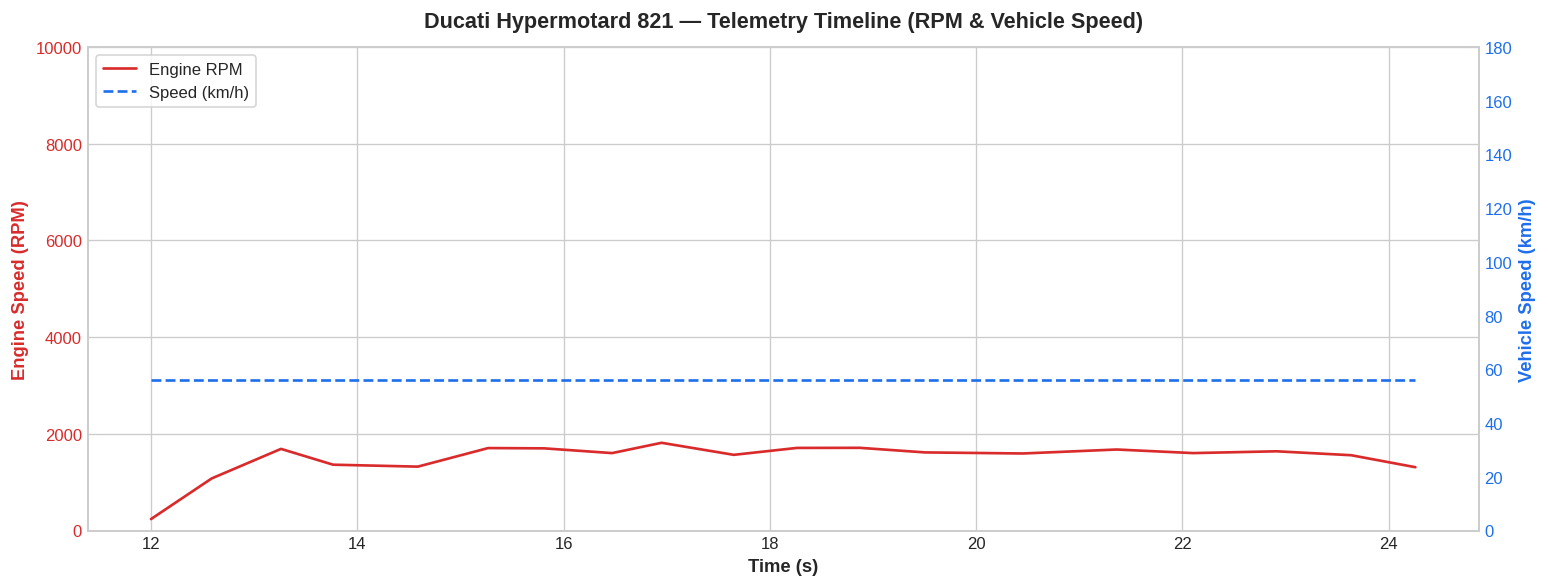

=== ESTIMATED AFR TABLE (Rows: TPS %, Columns: RPM) ===


RPM_Bin,1500
TPS_Bin,
10,18.45


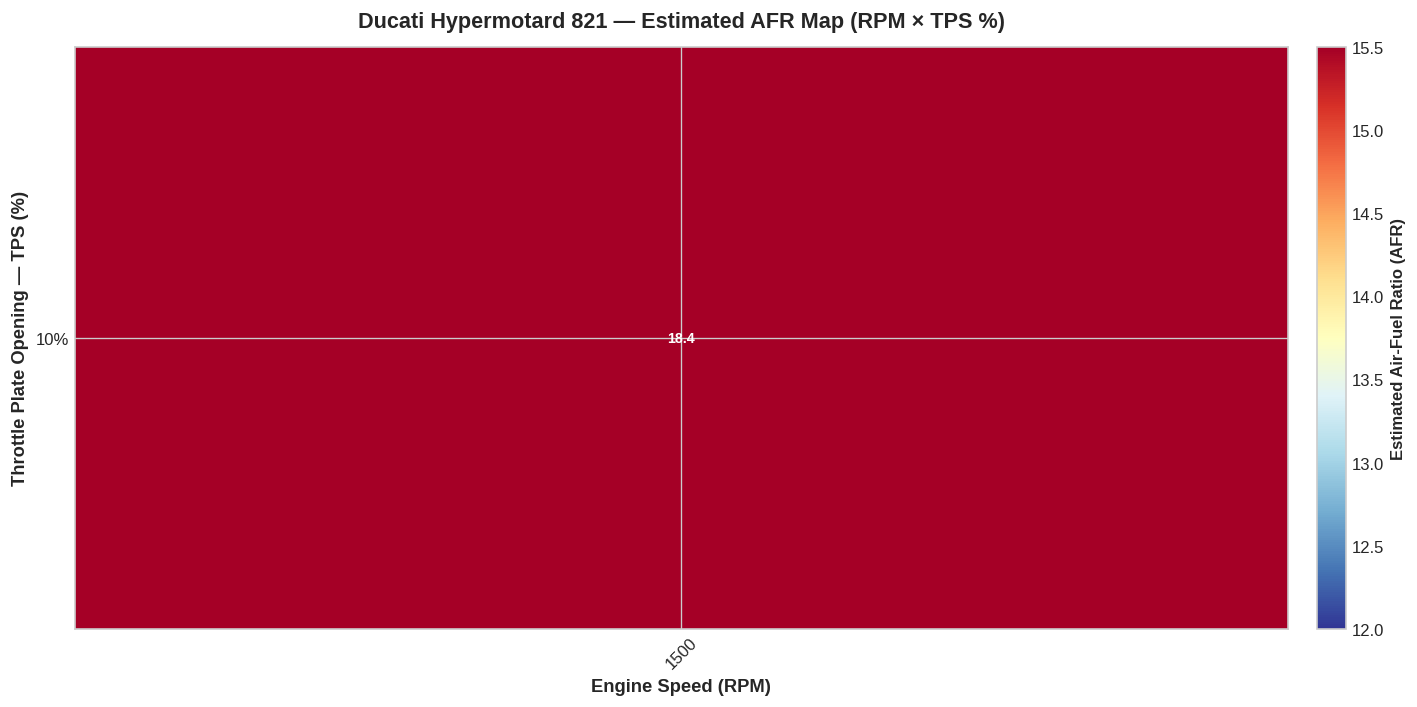

In [3]:
# %% [markdown]
# # Section 2: Telemetry Timeline & AFR Map Visualizations

# %%
# ---------------------------------------------------------
# 2. VISUALIZE THE RUN: TIME (X) VS SPEED & RPM (DUAL Y)
# ---------------------------------------------------------
fig, ax1 = plt.subplots(figsize=(13, 5))

color_rpm = "#D92B2B"   # Ducati Red
color_spd = "#1F6FEB"   # Telemetry Blue

ax1.set_xlabel("Time (s)", fontsize=11, fontweight="bold")
ax1.set_ylabel("Engine Speed (RPM)", color=color_rpm, fontsize=11, fontweight="bold")
line_rpm = ax1.plot(df["Time_s"], df["RPM"], color=color_rpm, linewidth=1.6, label="Engine RPM")
ax1.tick_params(axis="y", labelcolor=color_rpm)
ax1.set_ylim(0, max(10000, df["RPM"].max() * 1.1))

ax2 = ax1.twinx()
ax2.set_ylabel("Vehicle Speed (km/h)", color=color_spd, fontsize=11, fontweight="bold")
line_spd = ax2.plot(df["Time_s"], df["Speed_kmh"], color=color_spd, linewidth=1.6, linestyle="--", label="Speed (km/h)")
ax2.tick_params(axis="y", labelcolor=color_spd)
ax2.set_ylim(0, max(180, df["Speed_kmh"].max() * 1.15))
ax2.grid(False)

lines = line_rpm + line_spd
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="upper left", frameon=True)
plt.title("Ducati Hypermotard 821 — Telemetry Timeline (RPM & Vehicle Speed)", fontsize=13, fontweight="bold", pad=12)
fig.tight_layout()
plt.show()

# %%
# ---------------------------------------------------------
# 3. RPM & AFR TABLE WITH VALUES AND HEATMAP
# ---------------------------------------------------------
# Speed-Density Air Mass & Fuel Mass constants for 821cc Testastretta 11° (410.5 cc/cyl)
V_CYL_L = 0.4105          # Liters per cylinder
IAT_ASSUMED_C = 25.0      # Assumed airbox temp if IAT not logged (°C)
VE_EST = 0.88             # Baseline volumetric efficiency
INJ_FLOW_MG_MS = 3.65     # Injector flow rate (~300 cc/min -> ~3.65 mg/ms)
INJ_DEADTIME_MS = 0.85    # Injector opening deadtime (ms)

# Calculate per-cycle air mass (mg), fuel mass (mg), and Estimated AFR
air_mass_mg = (df["MAP1_kPa"] * V_CYL_L * 28.97) / (8.314 * (IAT_ASSUMED_C + 273.15)) * VE_EST * 1000.0
fuel_mass_mg = np.where(df["Inj1_ms"] > INJ_DEADTIME_MS, (df["Inj1_ms" ] - INJ_DEADTIME_MS) * INJ_FLOW_MG_MS, np.nan)
df["Est_AFR"] = np.clip(air_mass_mg / fuel_mass_mg, 10.0, 18.5)

# Bin RPM (500 RPM steps) and Throttle Position TPS (10% steps)
rpm_bins = np.arange(1500, 10000, 500)
tps_bins = np.arange(10, 110, 10)

valid_afr = df.dropna(subset=["Est_AFR", "RPM", "TPS_pct"]).copy()
valid_afr["RPM_Bin"] = pd.cut(valid_afr["RPM"], bins=rpm_bins, labels=rpm_bins[:-1])
valid_afr["TPS_Bin"] = pd.cut(valid_afr["TPS_pct"], bins=tps_bins, labels=tps_bins[:-1])

afr_table = valid_afr.pivot_table(
    index="TPS_Bin",
    columns="RPM_Bin",
    values="Est_AFR",
    aggfunc="mean",
    observed=False,
).sort_index(ascending=False)

print("=== ESTIMATED AFR TABLE (Rows: TPS %, Columns: RPM) ===")
display(afr_table.round(2))

# Render Annotated Heatmap
fig, ax = plt.subplots(figsize=(13, 6))
data_matrix = afr_table.to_numpy(dtype=float)
masked_data = np.ma.masked_invalid(data_matrix)

cmap = plt.cm.RdYlBu_r.copy()  # Red = Lean, Yellow = Stoich (~13.8-14.7), Blue = Rich
cmap.set_bad(color="#F2F2F2")

im = ax.imshow(masked_data, aspect="auto", cmap=cmap, vmin=12.0, vmax=15.5)
cbar = plt.colorbar(im, ax=ax, pad=0.02)
cbar.set_label("Estimated Air-Fuel Ratio (AFR)", fontsize=10, fontweight="bold")

ax.set_xticks(np.arange(len(afr_table.columns)))
ax.set_xticklabels(afr_table.columns.astype(str), rotation=45)
ax.set_yticks(np.arange(len(afr_table.index)))
ax.set_yticklabels([f"{int(y)}%" for y in afr_table.index])
ax.set_xlabel("Engine Speed (RPM)", fontsize=11, fontweight="bold")
ax.set_ylabel("Throttle Plate Opening — TPS (%)", fontsize=11, fontweight="bold")
ax.set_title("Ducati Hypermotard 821 — Estimated AFR Map (RPM × TPS %)", fontsize=13, fontweight="bold", pad=12)

# Print exact AFR values inside populated cells
for i in range(data_matrix.shape[0]):
    for j in range(data_matrix.shape[1]):
        val = data_matrix[i, j]
        if not np.isnan(val):
            text_color = "white" if (val < 12.6 or val > 15.0) else "black"
            ax.text(j, i, f"{val:.1f}", ha="center", va="center", color=text_color, fontsize=8.5, fontweight="bold")

fig.tight_layout()
plt.show()

In [4]:
# %% [markdown]
# # Section 3: Virtual Road Dyno Curve (HP & Torque)

# %%
# ---------------------------------------------------------
# 4. VIRTUAL ROAD DYNO: RPM (X) VS TORQUE NM & HP (DUAL Y)
# ---------------------------------------------------------
# Hypermotard 821 Physical & Aerodynamic Constants
MASS_KG = 278.0           # Bike wet weight (~198 kg) + rider & gear (~80 kg)
CD_A = 0.56               # Upright supermoto drag area (Cd * Frontal Area, m^2)
RHO_AIR = 1.18            # Air density (~400m elevation, kg/m^3)
C_RR = 0.015              # Motorcycle tire rolling resistance coefficient
DRIVETRAIN_LOSS = 0.10    # Chain/sprocket loss (10% -> Wheel / 0.90 = Crank)
G = 9.80665

dyno_df = df.copy()
# Calculate active gear from Speed / (RPM / 1000)
ratio = np.where(dyno_df["RPM" ] > 1000, dyno_df["Speed_kmh"] / (dyno_df["RPM"] / 1000.0), 0.0)
gear_centers = np.array([11.5, 14.2, 16.9, 19.7, 22.2, 24.5])
dyno_df["Est_Gear"] = np.where(
    ratio > 8.0,
    np.argmin(np.abs(ratio[:, None] - gear_centers[None, :]), axis=1) + 1,
    0,
)

# Smooth speed slightly before taking derivative dv/dt
dyno_df["v_ms"] = (dyno_df["Speed_kmh"] / 3.6).rolling(window=3, center=True, min_periods=1).mean()
dt = dyno_df["Time_s"].diff()
dv = dyno_df["v_ms"].diff()
dyno_df["accel_ms2"] = np.where((dt > 0.03) & (dt < 1.0), dv / dt, np.nan)

# Keep single-gear positive acceleration rows (WOT if available, else strongest pull in log)
wot_mask = (dyno_df["Twistgrip_pct"] >= 80) & (dyno_df["accel_ms2"] > 0.2) & (dyno_df["Est_Gear"] >= 2)
if wot_mask.sum() < 5:
    print("Note: Fewer than 5 WOT (Twistgrip >= 80%) rows found; plotting best acceleration pull in log.")
    wot_mask = (dyno_df["Twistgrip_pct"] >= 25) & (dyno_df["accel_ms2"] > 0.2) & (dyno_df["Est_Gear"] >= 2)

pull = dyno_df[wot_mask].copy()
# Select the gear with the most pull data points so shifts don't distort acceleration
if not pull.empty:
    target_gear = pull["Est_Gear"].mode()[0]
    pull = pull[pull["Est_Gear"] == target_gear].copy()

    # Physics forces & power
    f_accel = MASS_KG * pull["accel_ms2"]
    f_aero = 0.5 * RHO_AIR * CD_A * (pull["v_ms"] ** 2)
    f_roll = MASS_KG * G * C_RR
    f_total = f_accel + f_aero + f_roll

    p_wheel_w = f_total * pull["v_ms"]
    pull["Crank_HP"] = (p_wheel_w / 745.7) / (1.0 - DRIVETRAIN_LOSS)
    pull["Crank_Nm"] = np.where(pull["RPM"] > 0, (pull["Crank_HP" ] * 745.7 * 60.0) / (2.0 * np.pi * pull["RPM"]), np.nan)

    # Group into 250 RPM bins for a smooth dyno curve
    dyno_bins = np.arange(2000, 9750, 250)
    pull["RPM_Sweep"] = pd.cut(pull["RPM"], bins=dyno_bins, labels=dyno_bins[:-1] + 125)
    dyno_curve = pull.groupby("RPM_Sweep", observed=False)[["Crank_HP", "Crank_Nm"]].mean().dropna()
    dyno_curve.index = dyno_curve.index.astype(float)

    if not dyno_curve.empty:
        peak_hp = dyno_curve["Crank_HP"].max()
        peak_hp_rpm = dyno_curve["Crank_HP"].idxmax()
        peak_nm = dyno_curve["Crank_Nm"].max()
        peak_nm_rpm = dyno_curve["Crank_Nm"].idxmax()
        print(f"Peak Estimated Crank Power:  {peak_hp:.1f} hp @ {int(peak_hp_rpm)} RPM")
        print(f"Peak Estimated Crank Torque: {peak_nm:.1f} Nm @ {int(peak_nm_rpm)} RPM")
        fig, ax1 = plt.subplots(figsize=(12, 5.5))
        c_hp = "#D92B2B"   # Ducati Red for Horsepower
        c_nm = "#1F6FEB"   # Blue for Torque
        ax1.set_xlabel("Engine Speed (RPM)", fontsize=11, fontweight="bold")
        ax1.set_ylabel("Estimated Crank Power (hp)", color=c_hp, fontsize=11, fontweight="bold")
        l1 = ax1.plot(dyno_curve.index, dyno_curve["Crank_HP"], color=c_hp, marker="o", linewidth=2.4, label="Power (hp)")
        ax1.tick_params(axis="y", labelcolor=c_hp)
        ax1.set_ylim(0, max(125, peak_hp * 1.15))
        ax1.xaxis.set_major_locator(ticker.MultipleLocator(500))
        ax2 = ax1.twinx()
        ax2.set_ylabel("Estimated Crank Torque (Nm)", color=c_nm, fontsize=11, fontweight="bold")
        l2 = ax2.plot(dyno_curve.index, dyno_curve["Crank_Nm"], color=c_nm, marker="s", linestyle="--", linewidth=2.4, label="Torque (Nm)")
        ax2.tick_params(axis="y", labelcolor=c_nm)
        ax2.set_ylim(0, max(110, peak_nm * 1.2))
        ax2.grid(False)
        lines = l1 + l2
        ax1.legend(lines, [l.get_label() for l in lines], loc="upper left", frameon=True)
        plt.title(f"Ducati Hypermotard 821 — Virtual Road Dyno (Gear {int(target_gear)})", fontsize=13, fontweight="bold", pad=12)
        fig.tight_layout()
        plt.show()
    else:
        print("No data points left in dyno_curve sweep after binning. Try another log!")
else:
    print("No sustained acceleration pull found in the loaded CSV yet. Record a 2nd- or 3rd-gear pull and re-run!")

Note: Fewer than 5 WOT (Twistgrip >= 80%) rows found; plotting best acceleration pull in log.
No sustained acceleration pull found in the loaded CSV yet. Record a 2nd- or 3rd-gear pull and re-run!
